In [3]:
pip install ucimlrepo

In [4]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, GRU, Conv1D, Add, Activation, BatchNormalization, GlobalAveragePooling1D, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from ucimlrepo import fetch_ucirepo

np.random.seed(42)
tf.random.set_seed(42)
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
sns.set(style="whitegrid")

bike = fetch_ucirepo(id=275)
df = bike.data.features.copy()
df['cnt'] = bike.data.targets['cnt'].values
df['dteday'] = pd.to_datetime(df['dteday'])

daily = df.groupby('dteday').agg(
    cnt=('cnt', 'sum'),
    temp=('temp', 'mean'),
    hum=('hum', 'mean'),
    windspeed=('windspeed', 'mean'),
    weathersit=('weathersit', 'mean'),
    workingday=('workingday', 'first'),
).asfreq('D').interpolate('time').bfill().ffill()

daily['lag1']  = daily['cnt'].shift(1)
daily['lag7']  = daily['cnt'].shift(7)
daily['lag14'] = daily['cnt'].shift(14)
daily['roll7'] = daily['cnt'].shift(1).rolling(7).mean()
daily['roll30'] = daily['cnt'].shift(1).rolling(30).mean()
daily = daily.bfill()

TEST_SIZE = 60
TARGET = 'cnt'
train, test = daily.iloc[:-TEST_SIZE].copy(), daily.iloc[-TEST_SIZE:].copy()
next_day = daily.index[-1] + pd.Timedelta(days=1)

def metrics(y_true, y_pred, name):
    y_true, y_pred = np.asarray(y_true).ravel(), np.asarray(y_pred).ravel()
    return {
        "Model": name,
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE": np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100,
        "R2":   r2_score(y_true, y_pred),
    }

def clip0(a):
    return np.maximum(np.asarray(a).ravel(), 0)

In [5]:
EXOG = ['temp', 'hum', 'windspeed']

def arima_walk(train_s, test_s, tr_ex, te_ex, order=(1,0,1), seas=(1,0,0,7)):
    hist, hist_ex = list(train_s.values), list(tr_ex.values)
    preds = []
    for t in range(len(test_s)):
        try:
            m = SARIMAX(hist, exog=np.array(hist_ex),
                        order=order, seasonal_order=seas,
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False, maxiter=50)
            pred_val = m.forecast(1, exog=te_ex.values[t].reshape(1,-1))
            preds.append(float(pred_val[0]) if not hasattr(pred_val, 'iloc') else float(pred_val.iloc[0]))
        except Exception:
            preds.append(hist[-1])
        hist.append(test_s.values[t])
        hist_ex.append(te_ex.values[t])
    return np.array(preds)

def arima_next(train_s, tr_ex, last_ex, order=(1,0,1), seas=(1,0,0,7)):
    m = SARIMAX(train_s.values, exog=tr_ex.values,
                order=order, seasonal_order=seas,
                enforce_stationarity=False,
                enforce_invertibility=False).fit(disp=False, maxiter=50)
    pred_val = m.forecast(1, exog=last_ex.reshape(1,-1))
    return float(pred_val[0]) if not hasattr(pred_val, 'iloc') else float(pred_val.iloc[0])

arima_pred_test = arima_walk(train[TARGET], test[TARGET], train[EXOG], test[EXOG])
arima_m = metrics(test[TARGET], arima_pred_test, "ARIMA")
last_weather = daily[EXOG].iloc[-1].values
arima_fc1 = clip0([arima_next(daily[TARGET], daily[EXOG], last_weather)])[0]

In [6]:
LOOKBACK = 14
FEATURES = ['cnt', 'temp', 'hum', 'windspeed', 'weathersit',
            'workingday', 'lag1', 'lag7', 'lag14', 'roll7', 'roll30']

def add_cal(df):
    df = df.copy()
    doy, dow = df.index.dayofyear.values, df.index.dayofweek.values
    df['doy_sin'] = np.sin(2*np.pi*doy/365.25)
    df['doy_cos'] = np.cos(2*np.pi*doy/365.25)
    df['dow_sin'] = np.sin(2*np.pi*dow/7)
    df['dow_cos'] = np.cos(2*np.pi*dow/7)
    return df

ALL_FEATURES = FEATURES + ['doy_sin', 'doy_cos', 'dow_sin', 'dow_cos']

def make_seq(X, Y, lb):
    Xs, Ys = [], []
    for i in range(len(X) - lb):
        Xs.append(X[i:i+lb])
        Ys.append(Y[i+lb])
    return np.array(Xs), np.array(Ys)

def prep(train_df, test_df, lb=LOOKBACK):
    tr_c, te_c = add_cal(train_df), add_cal(test_df)
    sx = MinMaxScaler().fit(tr_c[ALL_FEATURES].values)
    sy = MinMaxScaler().fit(tr_c[[TARGET]].values)
    Xtr = sx.transform(tr_c[ALL_FEATURES].values)
    Xte = sx.transform(te_c[ALL_FEATURES].values)
    Ytr = sy.transform(tr_c[[TARGET]].values)
    Yte = sy.transform(te_c[[TARGET]].values)
    Xall, Yall = make_seq(np.vstack([Xtr, Xte]), np.vstack([Ytr, Yte]), lb)
    split = len(Xtr) - lb
    return Xall[:split], Yall[:split], Xall[split:], Yall[split:], sx, sy

def build_lstm():
    m = Sequential([
        Input((LOOKBACK, len(ALL_FEATURES))),
        LSTM(64, return_sequences=True, dropout=0.1, recurrent_dropout=0.1),
        LSTM(32, dropout=0.1),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    m.compile(Adam(2e-3), loss='mse')
    return m

def build_gru():
    m = Sequential([
        Input((LOOKBACK, len(ALL_FEATURES))),
        GRU(64, return_sequences=True, dropout=0.1, recurrent_dropout=0.1),
        GRU(32, dropout=0.1),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    m.compile(Adam(2e-3), loss='mse')
    return m

class TCNBlock(tf.keras.layers.Layer):
    def __init__(self, f, k, dil, drop=0.1, **kw):
        super().__init__(**kw)
        self.f, self.k, self.dil, self.drop = f, k, dil, drop
    def build(self, shape):
        self.c1 = Conv1D(self.f, self.k, dilation_rate=self.dil, padding='causal', activation='relu')
        self.c2 = Conv1D(self.f, self.k, dilation_rate=self.dil, padding='causal', activation='relu')
        self.d1 = SpatialDropout1D(self.drop)
        self.d2 = SpatialDropout1D(self.drop)
        self.b1, self.b2 = BatchNormalization(), BatchNormalization()
        self.down = Conv1D(self.f, 1, padding='causal') if shape[-1] != self.f else None
        self.add = Add(); self.act = Activation('relu')
        super().build(shape)
    def call(self, x, training=None):
        y = self.d1(self.b1(self.c1(x), training=training), training=training)
        y = self.d2(self.b2(self.c2(y), training=training), training=training)
        r = x if self.down is None else self.down(x)
        return self.act(self.add([y, r]))
    def get_config(self):
        c = super().get_config()
        c.update({'f':self.f,'k':self.k,'dil':self.dil,'drop':self.drop})
        return c

def build_tcn():
    inp = Input((LOOKBACK, len(ALL_FEATURES)))
    x = inp
    for d in (1, 2, 4):
        x = TCNBlock(32, 2, d, drop=0.15)(x)
    x = GlobalAveragePooling1D()(x)
    x = Dense(16, activation='relu')(x)
    out = Dense(1)(x)
    m = tf.keras.Model(inp, out)
    m.compile(Adam(2e-3), loss='mse')
    return m

def build_cnn_rnn():
    m = Sequential([
        Input((LOOKBACK, len(ALL_FEATURES))),
        Conv1D(64, 3, padding='same', activation='relu'),
        Dropout(0.15),
        GRU(32, dropout=0.1),
        Dense(16, activation='relu'),
        Dense(1)
    ])
    m.compile(Adam(2e-3), loss='mse')
    return m

def train_nn_model(build_fn, Xtr, Ytr, Xva, Yva):
    tf.random.set_seed(42); np.random.seed(42)
    m = build_fn()
    es = EarlyStopping(monitor='val_loss', patience=35, restore_best_weights=True)
    rl = ReduceLROnPlateau(monitor='val_loss', patience=10, factor=0.5, min_lr=1e-5)
    m.fit(Xtr, Ytr, validation_data=(Xva, Yva),
          epochs=250, batch_size=16, callbacks=[es, rl], verbose=0)
    return m

In [10]:
X_tr, Y_tr, X_te, Y_te, sx, sy = prep(train, test)
vs = int(len(X_tr) * 0.1)
Xtr_, Ytr_ = X_tr[:-vs], Y_tr[:-vs]
Xva_, Yva_ = X_tr[-vs:], Y_tr[-vs:]

lstm_m = train_nn_model(build_lstm, Xtr_, Ytr_, Xva_, Yva_)
gru_m  = train_nn_model(build_gru,  Xtr_, Ytr_, Xva_, Yva_)
tcn_m  = train_nn_model(build_tcn,  Xtr_, Ytr_, Xva_, Yva_)
cnn_rnn_m = train_nn_model(build_cnn_rnn, Xtr_, Ytr_, Xva_, Yva_)

pred_lstm = clip0(sy.inverse_transform(lstm_m.predict(X_te, verbose=0)).ravel())
pred_gru  = clip0(sy.inverse_transform(gru_m.predict(X_te, verbose=0)).ravel())
pred_tcn  = clip0(sy.inverse_transform(tcn_m.predict(X_te, verbose=0)).ravel())
pred_cnn_rnn = clip0(sy.inverse_transform(cnn_rnn_m.predict(X_te, verbose=0)).ravel())
y_true    = sy.inverse_transform(Y_te).ravel()

lstm_mt = metrics(y_true, pred_lstm, "LSTM")
gru_mt  = metrics(y_true, pred_gru,  "GRU")
tcn_mt = metrics(y_true, pred_tcn, "TCN")
cnn_rnn_mt = metrics(y_true, pred_cnn_rnn, "CNN+RNN")

In [11]:
def recursive_forecast(model, full_df, sx, sy, lb=LOOKBACK, steps=7):
    full_c = add_cal(full_df)
    X = sx.transform(full_c[ALL_FEATURES].values)
    window = X[-lb:].copy()
    last_date = full_df.index[-1]
    preds = []
    for h in range(1, steps + 1):
        yh = model.predict(window.reshape(1, lb, -1), verbose=0)[0, 0]
        preds.append(yh)
        next_date = last_date + pd.Timedelta(days=h)
        doy = next_date.dayofyear
        dow = next_date.dayofweek
        row = window[-1].copy()
        row[0] = yh
        row[-4] = np.sin(2*np.pi*doy/365.25)
        row[-3] = np.cos(2*np.pi*doy/365.25)
        row[-2] = np.sin(2*np.pi*dow/7)
        row[-1] = np.cos(2*np.pi*dow/7)
        window = np.vstack([window[1:], row])
    return sy.inverse_transform(np.array(preds).reshape(-1,1)).ravel()

full_c = add_cal(daily)
sx_full = MinMaxScaler().fit(full_c[ALL_FEATURES].values)
sy_full = MinMaxScaler().fit(full_c[[TARGET]].values)
Xall, Yall = make_seq(
    sx_full.transform(full_c[ALL_FEATURES].values),
    sy_full.transform(full_c[[TARGET]].values),
    LOOKBACK
)
vs = int(len(Xall) * 0.1)
Xtr_f, Ytr_f = Xall[:-vs], Yall[:-vs]
Xva_f, Yva_f = Xall[-vs:], Yall[-vs:]

lstm_f = train_nn_model(build_lstm, Xtr_f, Ytr_f, Xva_f, Yva_f)
gru_f  = train_nn_model(build_gru,  Xtr_f, Ytr_f, Xva_f, Yva_f)
tcn_f  = train_nn_model(build_tcn,  Xtr_f, Ytr_f, Xva_f, Yva_f)
cnn_rnn_f = train_nn_model(build_cnn_rnn, Xtr_f, Ytr_f, Xva_f, Yva_f)

FORECAST_STEPS = 7
lstm_fc = clip0(recursive_forecast(lstm_f, daily, sx_full, sy_full, steps=FORECAST_STEPS))
gru_fc  = clip0(recursive_forecast(gru_f,  daily, sx_full, sy_full, steps=FORECAST_STEPS))
tcn_fc  = clip0(recursive_forecast(tcn_f,  daily, sx_full, sy_full, steps=FORECAST_STEPS))
cnn_rnn_fc = clip0(recursive_forecast(cnn_rnn_f, daily, sx_full, sy_full, steps=FORECAST_STEPS))

lstm_fc1 = lstm_fc[0]
gru_fc1  = gru_fc[0]
tcn_fc1  = tcn_fc[0]
cnn_rnn_fc1 = cnn_rnn_fc[0]

2013-01-01 | ARIMA:     0 | LSTM:  3509 | GRU:  3585 | TCN:  3186 | CNN_RNN:  3381 | АНСАМБЛЬ:  2337
2013-01-02 | ARIMA:   710 | LSTM:  3634 | GRU:  3528 | TCN:  3009 | CNN_RNN:  3431 | АНСАМБЛЬ:  2555
2013-01-03 | ARIMA:     0 | LSTM:  3636 | GRU:  3318 | TCN:  2979 | CNN_RNN:  3662 | АНСАМБЛЬ:  2327
2013-01-04 | ARIMA:     0 | LSTM:  3501 | GRU:  3124 | TCN:  2340 | CNN_RNN:  3704 | АНСАМБЛЬ:  2175
2013-01-05 | ARIMA:  1698 | LSTM:  3338 | GRU:  2977 | TCN:  1348 | CNN_RNN:  3324 | АНСАМБЛЬ:  2436
2013-01-06 | ARIMA:     0 | LSTM:  3209 | GRU:  2964 | TCN:   468 | CNN_RNN:  3447 | АНСАМБЛЬ:  1755
2013-01-07 | ARIMA:     0 | LSTM:  3134 | GRU:  3047 | TCN:   112 | CNN_RNN:  2843 | АНСАМБЛЬ:  1596

Сводка метрик на тесте (60 дней):
              MAE      RMSE    MAPE     R2
Model                                     
ARIMA     822.244   999.546  27.598  0.602
LSTM     1077.201  1416.964  49.905  0.201
GRU       937.837  1323.178  49.274  0.303
TCN      1390.568  1587.411  55.142 -0.003


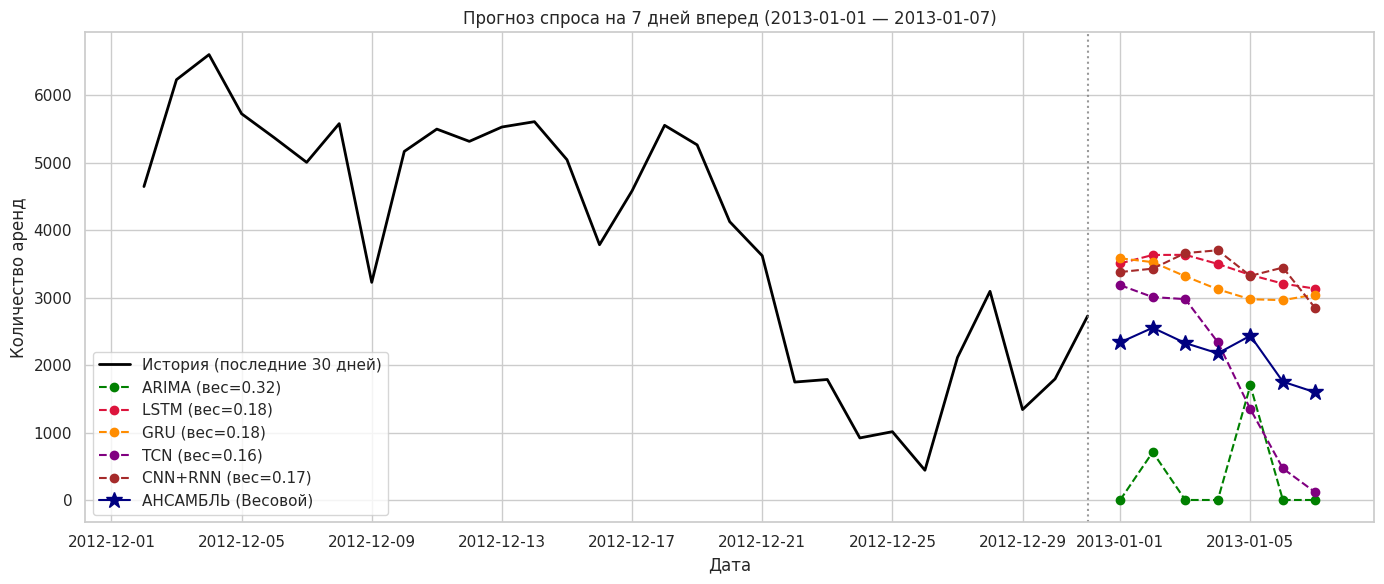

In [12]:
def arima_forecast_n(train_s, tr_ex, steps=7):
    m = SARIMAX(train_s.values, exog=tr_ex.values,
                order=(2,1,2), seasonal_order=(1,1,1,7),
                enforce_stationarity=False,
                enforce_invertibility=False,
                simple_differencing=True).fit(disp=False, maxiter=50)
    last_ex_tile = np.tile(tr_ex.iloc[-1].values, (steps, 1))
    pred_val = m.forecast(steps, exog=last_ex_tile)
    return np.array(pred_val)

arima_fc = clip0(arima_forecast_n(daily[TARGET], daily[EXOG], steps=FORECAST_STEPS))

mapes = np.array([arima_m['MAPE'], lstm_mt['MAPE'], gru_mt['MAPE'], tcn_mt['MAPE'], cnn_rnn_mt['MAPE']])
weights = 1 / (mapes + 1e-8)
weights /= weights.sum()

forecast_dates = [daily.index[-1] + pd.Timedelta(days=h) for h in range(1, FORECAST_STEPS + 1)]

ensemble_fc = (arima_fc * weights[0] +
               lstm_fc * weights[1] +
               gru_fc * weights[2] +
               tcn_fc * weights[3] +
               cnn_rnn_fc * weights[4])

for idx, day in enumerate(forecast_dates):
    print(f"{day.date()} | ARIMA: {arima_fc[idx]:>5.0f} | LSTM: {lstm_fc[idx]:>5.0f} | GRU: {gru_fc[idx]:>5.0f} | TCN: {tcn_fc[idx]:>5.0f} | CNN_RNN: {cnn_rnn_fc[idx]:>5.0f} | АНСАМБЛЬ: {ensemble_fc[idx]:>5.0f}")

summary = pd.DataFrame([arima_m, lstm_mt, gru_mt, tcn_mt, cnn_rnn_mt]).set_index("Model").round(3)
print("\nСводка метрик на тесте (60 дней):")
print(summary)

plt.figure(figsize=(14, 6))
h = daily[TARGET].iloc[-30:]
plt.plot(h.index, h.values, color='black', lw=2, label='История (последние 30 дней)')

plt.plot(forecast_dates, arima_fc, '--o', color='green', label=f'ARIMA (вес={weights[0]:.2f})')
plt.plot(forecast_dates, lstm_fc, '--o', color='crimson', label=f'LSTM (вес={weights[1]:.2f})')
plt.plot(forecast_dates, gru_fc, '--o', color='darkorange', label=f'GRU (вес={weights[2]:.2f})')
plt.plot(forecast_dates, tcn_fc, '--o', color='purple', label=f'TCN (вес={weights[3]:.2f})')
plt.plot(forecast_dates, cnn_rnn_fc, '--o', color='brown', label=f'CNN+RNN (вес={weights[4]:.2f})')
plt.plot(forecast_dates, ensemble_fc, '-*', color='navy', ms=12, label='АНСАМБЛЬ (Весовой)')

plt.axvline(daily.index[-1], color='gray', ls=':', alpha=0.8)
plt.title(f'Прогноз спроса на {FORECAST_STEPS} дней вперед ({forecast_dates[0].date()} — {forecast_dates[-1].date()})')
plt.xlabel('Дата')
plt.ylabel('Количество аренд')
plt.legend()
plt.tight_layout()
plt.show()